## Part A: Probability and Conceptual Foundation

#### Q1. What is Conditional Probability?

Conditional probability is the probability of an event occurring when another event has already occurred.

Formula: P(A|B) = P(A ∩ B) / P(B)

#### Q2. Explain Bayes' Theorem and its importance in classification.

Bayes' Theorem calculates the probability of an event using prior information. It is useful in classification because it helps predict the class of new data. Naive Bayes uses this theorem to classify messages as spam or legitimate.

#### Q3. What assumptions does the Naive Bayes Classifier make?

Naive Bayes assumes that all input features are conditionally independent given the target class. It uses Bayes' Theorem to calculate the probability of each class.

#### Q4. Explain the working principle of KNN and SVM.

K-Nearest Neighbors (KNN) classifies a new data point by finding its K nearest neighbors and assigning the most common class.

Support Vector Machine (SVM) finds the best decision boundary to separate different classes by maximizing the margin between them.

#### Q5. Compare distance-based, probabilistic, and margin-based classifiers.

Distance-based classifiers, such as KNN, classify data using distances between data points.

Probabilistic classifiers, such as Naive Bayes, use probability to predict classes.

Margin-based classifiers, such as SVM, find a decision boundary that maximizes the margin between different classes.

### Part - B : Dataset Understanding & Preprocessing

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [ ]:
df = pd.read_csv("data.csv")
df.head()

,message_id,message_text,message_length,word_count,num_urls,num_digits,num_special_chars,spam_keyword_score,legit_keyword_score,sender_activity_score,sender_account_age_days,messages_sent_last_24h,timestamp,hour_of_day,day_of_week,spam_label
0,900001,Please find the attached invoice for the updat...,99,11,1,4,0,0,1,56.6,500.0,6.0,2025-11-24 02:00:00,2,0,0
1,900002,Let's catch up tomorrow regarding the timeline...,73,12,0,0,0,0,0,16.6,207.0,0.0,2025-12-17 21:00:00,21,2,0
2,900003,Can you send the report by end of day? next Mo...,67,13,0,0,0,0,1,25.7,418.0,6.0,2025-11-15 13:00:00,13,5,0
3,900004,Can you send the report by end of day? 10:30 A...,64,13,0,4,0,0,1,48.8,276.0,5.0,2025-12-17 23:00:00,23,2,0
4,900005,Could you review the document and share feedba...,84,14,0,0,0,0,1,33.0,683.0,7.0,2025-11-29 11:00:00,11,5,0


In [8]:
print(df.columns)
print(df.shape)

X = df.drop("spam_label", axis=1)
y = df["spam_label"]

print("Input Features:")
display(X.head())

print("Target Variable:")
display(y.head())

Index(['message_id', 'message_text', 'message_length', 'word_count',
       'num_urls', 'num_digits', 'num_special_chars', 'spam_keyword_score',
       'legit_keyword_score', 'sender_activity_score',
       'sender_account_age_days', 'messages_sent_last_24h', 'timestamp',
       'hour_of_day', 'day_of_week', 'spam_label'],
      dtype='object')
(5200, 16)
Input Features:


,message_id,message_text,message_length,word_count,num_urls,num_digits,num_special_chars,spam_keyword_score,legit_keyword_score,sender_activity_score,sender_account_age_days,messages_sent_last_24h,timestamp,hour_of_day,day_of_week
0,900001,Please find the attached invoice for the updat...,99,11,1,4,0,0,1,56.6,500.0,6.0,2025-11-24 02:00:00,2,0
1,900002,Let's catch up tomorrow regarding the timeline...,73,12,0,0,0,0,0,16.6,207.0,0.0,2025-12-17 21:00:00,21,2
2,900003,Can you send the report by end of day? next Mo...,67,13,0,0,0,0,1,25.7,418.0,6.0,2025-11-15 13:00:00,13,5
3,900004,Can you send the report by end of day? 10:30 A...,64,13,0,4,0,0,1,48.8,276.0,5.0,2025-12-17 23:00:00,23,2
4,900005,Could you review the document and share feedba...,84,14,0,0,0,0,1,33.0,683.0,7.0,2025-11-29 11:00:00,11,5


Target Variable:


0    0
1    0
2    0
3    0
4    0
Name: spam_label, dtype: int64

In [11]:
print(df.isnull().sum())

X = X.fillna(X.median(numeric_only=True))
X = pd.get_dummies(X, drop_first=True)

display(X.head())

message_id                   0
message_text                 0
message_length               0
word_count                   0
num_urls                     0
num_digits                   0
num_special_chars            0
spam_keyword_score           0
legit_keyword_score          0
sender_activity_score      106
sender_account_age_days    113
messages_sent_last_24h     162
timestamp                    0
hour_of_day                  0
day_of_week                  0
spam_label                   0
dtype: int64


,message_id,message_length,word_count,num_urls,num_digits,num_special_chars,spam_keyword_score,legit_keyword_score,sender_activity_score,sender_account_age_days,...,timestamp_2025-12-23 15:00:00,timestamp_2025-12-23 16:00:00,timestamp_2025-12-23 17:00:00,timestamp_2025-12-23 18:00:00,timestamp_2025-12-23 19:00:00,timestamp_2025-12-23 20:00:00,timestamp_2025-12-23 21:00:00,timestamp_2025-12-23 22:00:00,timestamp_2025-12-23 23:00:00,timestamp_2025-12-24 00:00:00
0,900001,99,11,1,4,0,0,1,56.6,500.0,...,False,False,False,False,False,False,False,False,False,False
1,900002,73,12,0,0,0,0,0,16.6,207.0,...,False,False,False,False,False,False,False,False,False,False
2,900003,67,13,0,0,0,0,1,25.7,418.0,...,False,False,False,False,False,False,False,False,False,False
3,900004,64,13,0,4,0,0,1,48.8,276.0,...,False,False,False,False,False,False,False,False,False,False
4,900005,84,14,0,0,0,0,1,33.0,683.0,...,False,False,False,False,False,False,False,False,False,False


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4160, 2894)
Testing data: (1040, 2894)


### Part - C : Baseline Model – K-Nearest Neighbors (KNN)

In [12]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)

print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))

c:\Users\Priyansh\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Priyansh\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\Priyansh\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Priyansh\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\Priyansh\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _w

KNN Accuracy: 0.8144230769230769


In [13]:
for k in [3, 5, 7, 9, 11]:
    model = KNeighborsClassifier(n_neighbors=k)

    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    print("K =", k, "Accuracy =", accuracy_score(y_test, pred))

K = 3 Accuracy = 0.8153846153846154
K = 5 Accuracy = 0.8144230769230769
K = 7 Accuracy = 0.8125
K = 9 Accuracy = 0.8125
K = 11 Accuracy = 0.8125


In [14]:
for metric in ["euclidean", "manhattan"]:
    model = KNeighborsClassifier(n_neighbors=5, metric=metric)

    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    print(metric, "Accuracy:", accuracy_score(y_test, pred))

euclidean Accuracy: 0.8144230769230769
manhattan Accuracy: 0.8144230769230769


In [17]:
wrong = np.where(y_pred_knn != y_test.to_numpy())[0]

print("Misclassified messages:", len(wrong))
print("Misclassified test row indexes:", wrong)

results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred_knn
})

display(results[results["Actual"] != results["Predicted"]].head(10))

Misclassified messages: 193
Misclassified test row indexes: [   1   13   15   22   38   47   54   58   59   63   71   74   75   78
   80   82   84   85   89   91   95   97  100  111  119  120  129  132
  135  136  142  152  157  158  166  172  178  181  183  187  188  192
  196  207  208  230  231  235  253  266  269  289  299  304  309  316
  321  326  335  342  343  357  361  368  372  374  377  379  384  387
  393  394  398  403  415  417  422  424  427  431  432  434  440  454
  456  470  474  477  479  485  487  489  490  507  509  510  514  527
  528  532  535  543  546  552  555  557  559  560  562  563  567  574
  575  581  582  612  621  630  649  651  658  659  660  668  689  698
  700  701  706  708  710  721  735  739  745  747  749  754  760  762
  763  772  775  781  786  787  793  795  802  803  812  814  816  827
  828  831  832  838  846  848  859  869  871  875  884  889  893  894
  898  910  915  918  924  925  930  941  945  951  960  971  978  985
  996  997 1005 1

,Actual,Predicted
1,1,0
13,1,0
15,1,0
22,1,0
38,1,0
47,1,0
54,1,0
58,1,0
59,1,0
63,1,0


### Part D: Support Vector Machine (SVM)

In [18]:
svm_linear = SVC(kernel="linear")

svm_linear.fit(X_train, y_train)

y_pred_svm = svm_linear.predict(X_test)

print("Linear SVM Accuracy:", accuracy_score(y_test, y_pred_svm))

Linear SVM Accuracy: 0.9951923076923077


In [19]:
svm_rbf = SVC(kernel="rbf")

svm_rbf.fit(X_train, y_train)

y_pred_rbf = svm_rbf.predict(X_test)

print("RBF SVM Accuracy:", accuracy_score(y_test, y_pred_rbf))

RBF SVM Accuracy: 0.8298076923076924


In [20]:
print("Linear Kernel Accuracy:",
      accuracy_score(y_test, y_pred_svm))

print("RBF Kernel Accuracy:",
      accuracy_score(y_test, y_pred_rbf))

Linear Kernel Accuracy: 0.9951923076923077
RBF Kernel Accuracy: 0.8298076923076924


In [21]:
for c in [0.1, 1, 10, 100]:
    model = SVC(kernel="linear", C=c)

    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    print("C =", c, "Accuracy =", accuracy_score(y_test, pred))

C = 0.1 Accuracy = 0.9951923076923077
C = 1 Accuracy = 0.9951923076923077
C = 10 Accuracy = 0.9951923076923077
C = 100 Accuracy = 0.9951923076923077


### Part E: Probabilistic Model — Naive Bayes

In [22]:
nb = GaussianNB()

nb.fit(X_train, y_train)

y_pred_nb = nb.predict(X_test)

print("Naive Bayes Accuracy:", accuracy_score(y_test, y_pred_nb))

Naive Bayes Accuracy: 0.8817307692307692


In [23]:
y_prob = nb.predict_proba(X_test)

print("Class Labels:", nb.classes_)
print("First 5 Predictions:")
print(y_prob[:5])

Class Labels: [0 1]
First 5 Predictions:
[[1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]]


In [24]:
results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred_nb
})

print(results.head(10))

   Actual  Predicted
0       0          0
1       1          0
2       0          0
3       0          0
4       0          0
5       0          0
6       0          0
7       0          0
8       0          0
9       0          0


In [25]:
wrong = results[results["Actual"] != results["Predicted"]]

print("Misclassified Messages:", len(wrong))
print(wrong.head(10))

Misclassified Messages: 123
    Actual  Predicted
1        1          0
15       1          0
23       0          1
38       1          0
47       1          0
58       1          0
68       0          1
75       1          0
77       0          1
78       1          0


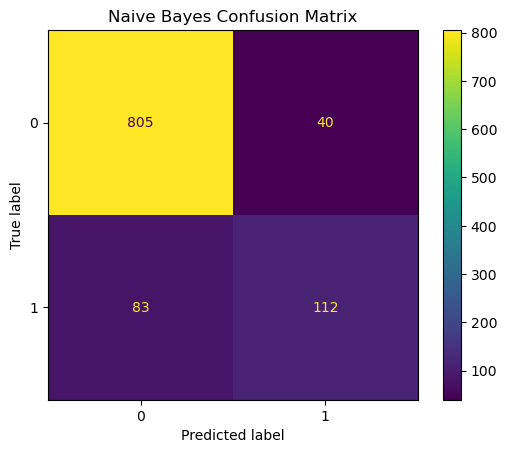

In [26]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_nb)

plt.title("Naive Bayes Confusion Matrix")
plt.show()

### Part F: Model Evaluation and Comparison

In [27]:
models = {
    "KNN": y_pred_knn,
    "SVM Linear": y_pred_svm,
    "SVM RBF": y_pred_rbf,
    "Naive Bayes": y_pred_nb
}

for name, pred in models.items():
    print("\n", name)
    print("Accuracy:", accuracy_score(y_test, pred))
    print("Precision:", precision_score(y_test, pred, zero_division=0))
    print("Recall:", recall_score(y_test, pred, zero_division=0))
    print("F1 Score:", f1_score(y_test, pred, zero_division=0))


 KNN
Accuracy: 0.8144230769230769
Precision: 1.0
Recall: 0.010256410256410256
F1 Score: 0.02030456852791878

 SVM Linear
Accuracy: 0.9951923076923077
Precision: 1.0
Recall: 0.9743589743589743
F1 Score: 0.987012987012987

 SVM RBF
Accuracy: 0.8298076923076924
Precision: 0.6451612903225806
Recall: 0.20512820512820512
F1 Score: 0.311284046692607

 Naive Bayes
Accuracy: 0.8817307692307692
Precision: 0.7368421052631579
Recall: 0.5743589743589743
F1 Score: 0.6455331412103746


In [29]:
results = []

for name, pred in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0)
    })

comparison = pd.DataFrame(results)

display(comparison)

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,0.814423,1.000000,0.010256,0.020305
1,SVM Linear,0.995192,1.000000,0.974359,0.987013
2,SVM RBF,0.829808,0.645161,0.205128,0.311284
3,Naive Bayes,0.881731,0.736842,0.574359,0.645533


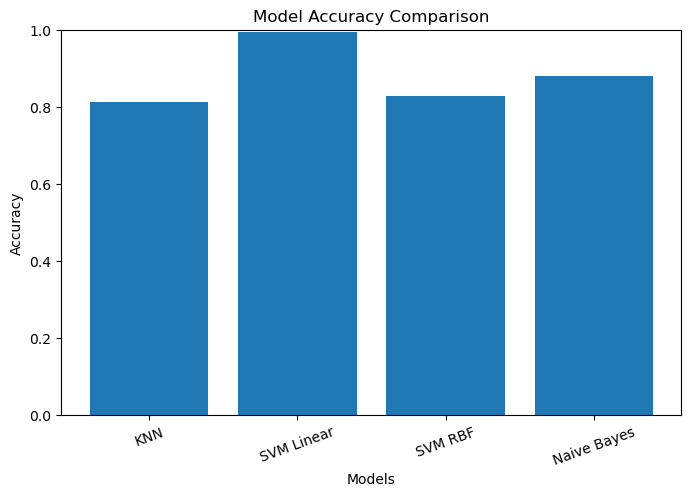

In [30]:
plt.figure(figsize=(8, 5))

plt.bar(comparison["Model"], comparison["Accuracy"])

plt.title("Model Accuracy Comparison")
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)

plt.show()

In [31]:
best_model = comparison.loc[
    comparison["F1 Score"].idxmax()
]

print("Best Model:", best_model["Model"])
print("F1 Score:", best_model["F1 Score"])

Best Model: SVM Linear
F1 Score: 0.987012987012987


### Part G: Error Analysis and Misclassified Messages

In [33]:
wrong = X_test.shape[0]

errors = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred_svm
})

errors = errors[errors["Actual"] != errors["Predicted"]]

print("Total Test Messages:", wrong)
print("Misclassified Messages:", len(errors))
display(errors.head(10))

Total Test Messages: 1040
Misclassified Messages: 5


,Actual,Predicted
1,1,0
120,1,0
575,1,0
659,1,0
812,1,0


In [34]:
cm = confusion_matrix(y_test, y_pred_svm)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[845   0]
 [  5 190]]


In [35]:
tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

True Negatives: 845
False Positives: 0
False Negatives: 5
True Positives: 190


In [37]:
X_test_df = pd.DataFrame(
    X_test,
    columns=X.columns
)

X_test_df = X_test_df.reset_index(drop=True)

error_details = X_test_df.copy()
error_details["Actual"] = y_test.reset_index(drop=True)
error_details["Predicted"] = y_pred_svm

display(error_details[
    error_details["Actual"] != error_details["Predicted"]
].head(10))

,message_id,message_length,word_count,num_urls,num_digits,num_special_chars,spam_keyword_score,legit_keyword_score,sender_activity_score,sender_account_age_days,...,timestamp_2025-12-23 17:00:00,timestamp_2025-12-23 18:00:00,timestamp_2025-12-23 19:00:00,timestamp_2025-12-23 20:00:00,timestamp_2025-12-23 21:00:00,timestamp_2025-12-23 22:00:00,timestamp_2025-12-23 23:00:00,timestamp_2025-12-24 00:00:00,Actual,Predicted
1,-1.292565,-1.059030,-0.287942,-0.506377,-0.691370,1.382133,-0.367381,-1.47168,-0.790881,-1.489486,...,-0.015506,-0.015506,-0.031024,-0.021932,-0.046563,-0.021932,-0.031024,-0.031024,1,0
120,1.438052,1.614397,1.574947,1.974812,0.970635,1.382133,-0.367381,-1.47168,-0.232142,-0.101478,...,-0.015506,-0.015506,-0.031024,-0.021932,-0.046563,-0.021932,-0.031024,-0.031024,1,0
575,-1.125861,-1.059030,0.953984,-0.506377,-0.691370,1.382133,-0.367381,-1.47168,2.094035,-1.462997,...,-0.015506,-0.015506,-0.031024,-0.021932,-0.046563,-0.021932,-0.031024,-0.031024,1,0
659,0.387815,-1.221056,-0.287942,-0.506377,-0.691370,1.382133,1.097917,-1.47168,0.491938,-0.424640,...,-0.015506,-0.015506,-0.031024,-0.021932,-0.046563,-0.021932,-0.031024,-0.031024,1,0
812,-0.647086,1.938449,2.195910,1.974812,0.970635,1.382133,-0.367381,-1.47168,-0.540019,-1.309363,...,-0.015506,-0.015506,-0.031024,-0.021932,-0.046563,-0.021932,-0.031024,-0.031024,1,0


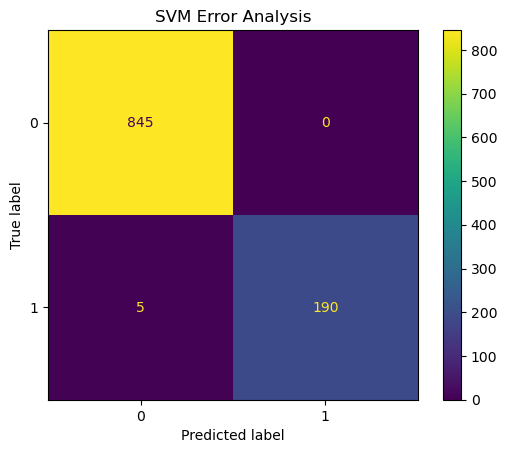

In [38]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_svm
)

plt.title("SVM Error Analysis")
plt.show()

## Conclusion

In this project, different machine learning algorithms were used to classify messages as spam or legitimate.

1. KNN classified messages using distance.
2. SVM classified messages using decision boundaries and kernels.
3. Naive Bayes classified messages using probability.
4. Accuracy, precision, recall, and F1-score were used to evaluate the models.
5. A confusion matrix was used to identify classification errors.

The performance of all models was compared to identify the best-performing classifier. The best model was selected based on its evaluation metrics.

This project demonstrates how machine learning can help detect spam messages and improve message classification.

In [41]:
display(comparison)

print("Best Model:", best_model["Model"])
print("Accuracy:", best_model["Accuracy"])
print("Precision:", best_model["Precision"])
print("Recall:", best_model["Recall"])
print("F1 Score:", best_model["F1 Score"])

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,0.814423,1.000000,0.010256,0.020305
1,SVM Linear,0.995192,1.000000,0.974359,0.987013
2,SVM RBF,0.829808,0.645161,0.205128,0.311284
3,Naive Bayes,0.881731,0.736842,0.574359,0.645533


Best Model: SVM Linear
Accuracy: 0.9951923076923077
Precision: 1.0
Recall: 0.9743589743589743
F1 Score: 0.987012987012987
